In [1]:
# ===========================================
# Import Required Libraries
# ===========================================

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# ===========================================
# Load Dataset
# ===========================================

inputs = np.load("../data/raw/inputs.npy")
labels = np.load("../data/raw/labels.npy")

print(inputs.shape)
print(labels.shape)

(1530, 27, 6000)
(1530,)


In [3]:
# ===========================================
# Train-Test Split
# ===========================================

X_train, X_test, y_train, y_test = train_test_split(
    inputs,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print(X_train.shape)
print(X_test.shape)

(1224, 27, 6000)
(306, 27, 6000)


In [4]:
def extract_features(sample):

    features = []

    for sensor in sample:

        mean = np.mean(sensor)
        std = np.std(sensor)
        rms = np.sqrt(np.mean(sensor**2))
        maximum = np.max(sensor)
        minimum = np.min(sensor)
        peak_to_peak = np.ptp(sensor)
        energy = np.sum(sensor**2)

        features.extend([
            mean,
            std,
            rms,
            maximum,
            minimum,
            peak_to_peak,
            energy
        ])

    return np.array(features)

In [5]:
X_train_features = np.array([extract_features(sample) for sample in X_train])

X_test_features = np.array([extract_features(sample) for sample in X_test])

print(X_train_features.shape)
print(X_test_features.shape)

(1224, 189)
(306, 189)


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_features)

X_test_scaled = scaler.transform(X_test_features)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(1224, 189)
(306, 189)


In [7]:
# ===========================================
# One-Hot Encode Labels
# ===========================================

y_train_cat = to_categorical(y_train)

y_test_cat = to_categorical(y_test)

print("Training Labels:", y_train_cat.shape)
print("Testing Labels :", y_test_cat.shape)

Training Labels: (1224, 17)
Testing Labels : (306, 17)


In [9]:
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Input(shape=(189,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(17, activation='softmax')
])

In [10]:
# Display the model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        24,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,681 (131.57 KB)

 Trainable params: 33,681 (131.57 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# ===========================================
# Compile the Neural Network
# ===========================================

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
# ===========================================
# Train the Neural Network
# ===========================================

history = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.2799 - loss: 2.5354 - val_accuracy: 0.5102 - val_loss: 2.0010
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6251 - loss: 1.6183 - val_accuracy: 0.6776 - val_loss: 1.3548
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8049 - loss: 1.0156 - val_accuracy: 0.7878 - val_loss: 0.8847
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8907 - loss: 0.6327 - val_accuracy: 0.8857 - val_loss: 0.6002
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9356 - loss: 0.4122 - val_accuracy: 0.9306 - val_loss: 0.4062
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9642 - loss: 0.2870 - val_accuracy: 0.9551 - val_loss: 0.3124
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9826 - loss: 0.2004 - val_accuracy: 0.9796 - val_loss: 0.2344
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9857 - loss: 0.1493 - val_accuracy: 0.9796 - val_loss

In [13]:
# ===========================================
# Evaluate the Model on Test Data
# ===========================================

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test_cat,
    verbose=0
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

Test Loss     : 0.0377
Test Accuracy : 0.9935


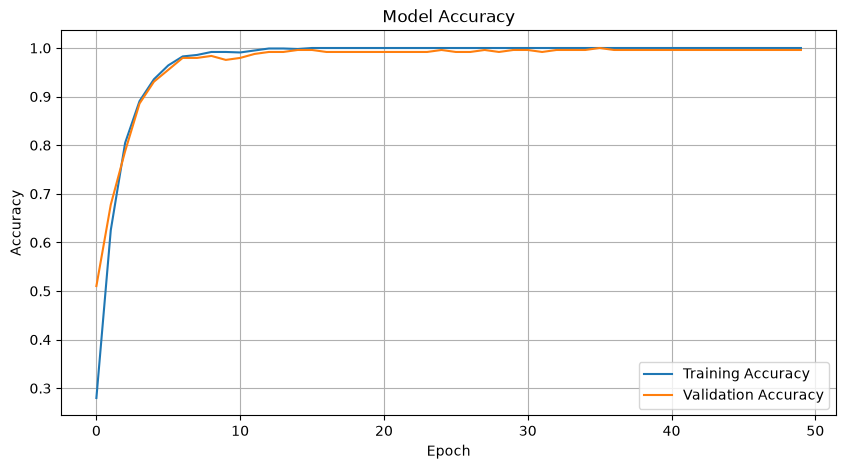

In [14]:
# ===========================================
# Plot Training and Validation Accuracy
# ===========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

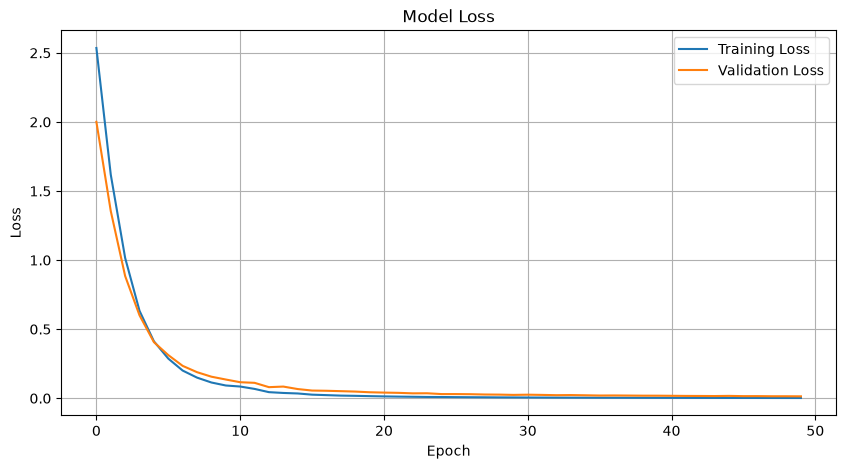

In [15]:
# ===========================================
# Plot Training and Validation Loss
# ===========================================

plt.figure(figsize=(10,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [16]:
# ===========================================
# Generate Predictions
# ===========================================

y_pred_prob = model.predict(X_test_scaled)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = np.argmax(y_test_cat, axis=1)

print("Predicted Labels:")
print(y_pred[:10])

print("\nActual Labels:")
print(y_true[:10])

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Predicted Labels:
[16 16  6 11 15 13  9  8  7  0]

Actual Labels:
[16 16  6 11 15 13  9  8  7  0]


<Figure size 1000x1000 with 0 Axes>

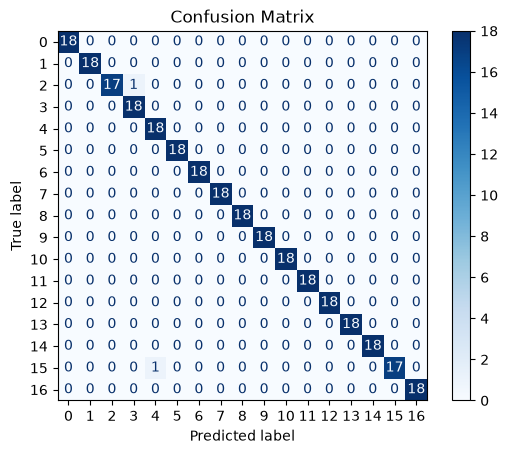

In [17]:
# ===========================================
# Confusion Matrix
# ===========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(17)
)

plt.figure(figsize=(10,10))
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [18]:
# ===========================================
# Classification Report
# ===========================================

from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      1.00      1.00        18
           2       1.00      0.94      0.97        18
           3       0.95      1.00      0.97        18
           4       0.95      1.00      0.97        18
           5       1.00      1.00      1.00        18
           6       1.00      1.00      1.00        18
           7       1.00      1.00      1.00        18
           8       1.00      1.00      1.00        18
           9       1.00      1.00      1.00        18
          10       1.00      1.00      1.00        18
          11       1.00      1.00      1.00        18
          12       1.00      1.00      1.00        18
          13       1.00      1.00      1.00        18
          14       1.00      1.00      1.00        18
          15       1.00      0.94      0.97        18
          16       1.00      1.00      1.00        18

    accuracy              

In [19]:
# ===========================================
# Save the Neural Network
# ===========================================

model.save("../models/bridge_damage_classifier.keras")

print("Model saved successfully!")

Model saved successfully!


In [20]:
# ===========================================
# Save the StandardScaler
# ===========================================

import joblib

joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("Scaler saved successfully!")

Scaler saved successfully!
